# Evaluation of optimized version of LBM D2Q9

## Simulation parameters:
* Re    = ~1000
* $\omega$ = 1.7
* v$_{N}$(x)  = 0.1
* L     = 300

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import re

from pathlib import Path

## Results visualization

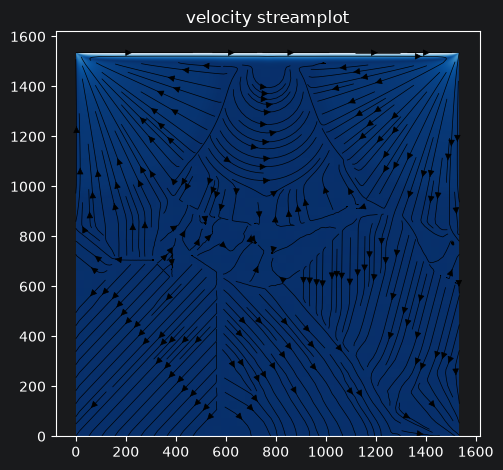

In [2]:
parent = '../out/bw_scaling_1536_spread'
file_base = "re1000-"
ext = ".tsv"

def _frame_generator(filename):
    """
    Zwraca kolejne DataFrame'y odpowiadające jednemu timestepowi.
    """

    reader = pd.read_csv(
        filename,
        sep = "\t",
        names = ["omega", "t", "y", "x", "rho", "uy", "ux"],
        chunksize = 4096,
    )

    buffer = pd.DataFrame()
    for chunk in reader:
        buffer = pd.concat([buffer, chunk], ignore_index=True)
        while len(buffer):
            t = buffer.iloc[0]["t"]
            mask = buffer["t"] == t
            # cały bufor należy do jednego timestepu
            if mask.all():
                break
            yield buffer[mask].copy()
            buffer = buffer[~mask].reset_index(drop=True)

    if len(buffer):
        yield buffer

def log_frame_reader(n):
    path = Path(parent) / str(n) / file_base
    stem = path.name

    pattern = re.compile( rf"{re.escape(stem)}(\d+){re.escape(ext)}$" )
    readers = []

    for file in sorted(path.parent.iterdir()):
        if not pattern.match(file.name):
            continue
        if file.stat().st_size == 0:
            continue
        readers.append(_frame_generator(file))

    if not readers:
        raise FileNotFoundError(f"No log files found for {stem}")

    while True:
        frames = []
        for reader in readers:
            try:
                frames.append(next(reader))
            except StopIteration:
                pass
        if not frames:
            break
        yield (
            pd.concat(frames, ignore_index=True)
              .sort_values(["y", "x"])
              .reset_index(drop=True)
        )


def field_streamplot(n, density=0.5):
    frames = log_frame_reader(n)
    frame = next(frames)

    square = frame['t'].values.size
    Nx = int(np.sqrt(square))

    x, y = np.meshgrid(np.arange(Nx), np.arange(Nx))
    ux = frame['ux'].values.reshape(Nx, Nx)
    uy = frame['uy'].values.reshape(Nx, Nx)
    speed = np.sqrt(ux**2 + uy**2)

    plt.imshow(speed, cmap="Blues_r")
    plt.streamplot(
            x, y, ux, uy,
            density = density,
            linewidth= 0.5,
            color = 'black'
    )
    plt.gca().invert_yaxis()

    plt.title(f"velocity streamplot")
    plt.tight_layout()
    plt.show()


field_streamplot(4, density=2.0)

## scaling results

In [3]:
def get_df(path):
    return pd.read_csv(
            path,
            sep = "\t",
            names = ["n", "i", "MLUPS", "total", "copy", "sync", "communication", "collision"]
    )


def get_avg_agg(df):
    return (
        df.groupby("n", as_index = False)
          .agg({
              "MLUPS"	        : "mean",
              "total"	        : "mean",
              "copy"		    : "mean",
              "sync"            : "mean",
              "communication"	: "mean",
              "collision"		: "mean",
          })
    )

def get_max_agg(df):
    return (
        df.groupby("n", as_index = False)
          .agg({
              "MLUPS"	        : "max",
              "total"	        : "max",
              "copy"		    : "max",
              "sync"            : "max",
              "communication"	: "max",
              "collision"		: "max",
          })
    )

In [4]:
df = get_df('../out/bw_scaling_1536_spread/stats.tsv')
avg = get_avg_agg(df)
max_agg = get_max_agg(df)

In [5]:
df_dense = get_df('../out/bw_scaling_1536/stats.tsv')
avg_dense = get_avg_agg(df_dense)
max_dense = get_max_agg(df_dense)

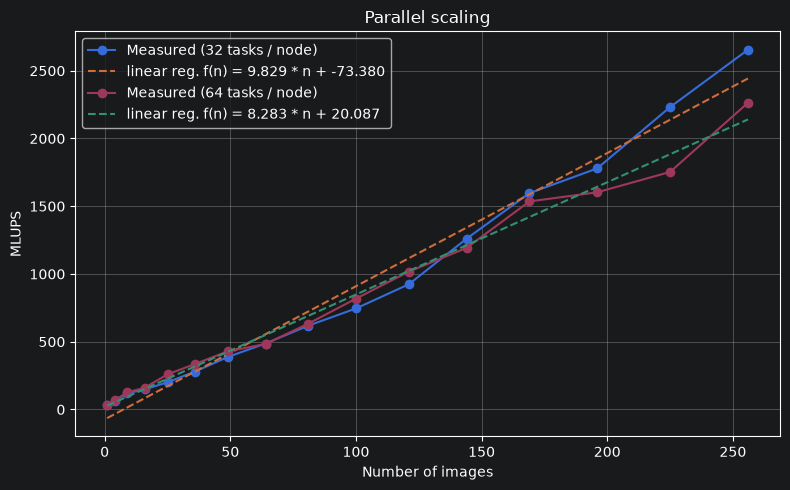

In [11]:
# Scaling
plt.figure(figsize=(8, 5))

a, b = np.polyfit(avg['n'], avg['MLUPS'], 1)
plt.plot(avg['n'], avg['MLUPS'], "o-", label="Measured (32 tasks / node)")
plt.plot(avg['n'], a * avg['n'] + b, '--', label=f'linear reg. f(n) = {a:.3f} * n + {b:.3f}')

a, b = np.polyfit(avg_dense['n'], avg_dense['MLUPS'], 1)
plt.plot(avg_dense['n'], avg_dense['MLUPS'], "o-", label="Measured (64 tasks / node)")
plt.plot(avg_dense['n'], a * avg_dense['n'] + b, '--', label=f'linear reg. f(n) = {a:.3f} * n + {b:.3f}')


# node_limits = [
#     (72.5,  "2 nodes"),
#     (132.5, "3 nodes"),
#     (182.5, "4 nodes")
# ]
# y_max = plt.ylim()[0] + 5
# for x, label in node_limits:
#     plt.axvline(x=x, color="red", linestyle="--", linewidth=1.2, alpha=0.8)
#     plt.text(x=x, y=y_max, s=label, rotation=0, ha="center", va="bottom", fontsize=9, bbox=dict(facecolor="black", edgecolor="none", alpha=0.8))

plt.xlabel("Number of images")
plt.ylabel("MLUPS")
plt.title("Parallel scaling")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

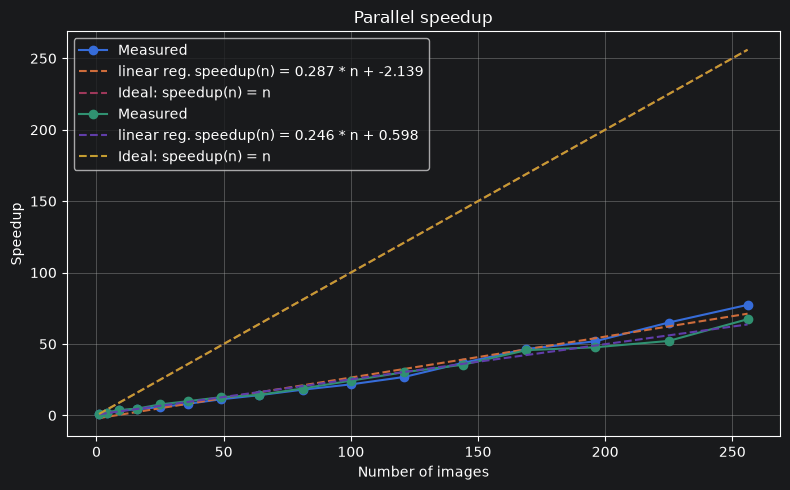

In [12]:
# Speedup
plt.figure(figsize=(8, 5))

speedup = avg['MLUPS'] / avg[avg['n'] == 1]['MLUPS'].values[0]
a, b = np.polyfit(avg['n'], speedup, 1)
plt.plot(avg['n'], speedup, "o-", label="Measured")
plt.plot(avg['n'], a * avg['n'] + b, '--', label=f'linear reg. speedup(n) = {a:.3f} * n + {b:.3f}')
plt.plot(avg['n'], avg['n'], "--", label="Ideal: speedup(n) = n")

speedup = avg_dense['MLUPS'] / avg_dense[avg['n'] == 1]['MLUPS'].values[0]
a, b = np.polyfit(avg_dense['n'], speedup, 1)
plt.plot(avg_dense['n'], speedup, "o-", label="Measured")
plt.plot(avg_dense['n'], a * avg_dense['n'] + b, '--', label=f'linear reg. speedup(n) = {a:.3f} * n + {b:.3f}')
plt.plot(avg_dense['n'], avg_dense['n'], "--", label="Ideal: speedup(n) = n")

plt.xlabel("Number of images")
plt.ylabel("Speedup")
plt.title("Parallel speedup")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

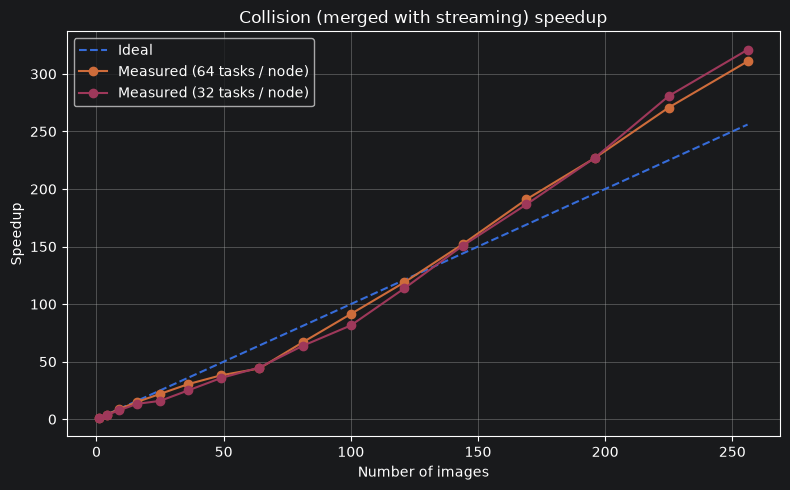

In [13]:
# Collision speedup
plt.figure(figsize=(8, 5))

plt.plot(avg['n'], avg['n'], "--", label="Ideal")

speedup = float(avg_dense[avg_dense['n'] == 1]['collision'].values[0]) / avg_dense['collision']
plt.plot(avg_dense['n'], speedup, "o-", label="Measured (64 tasks / node)")

speedup = float(avg[avg['n'] == 1]['collision'].values[0]) / avg['collision']
plt.plot(avg['n'], speedup, "o-", label="Measured (32 tasks / node)")

plt.xlabel("Number of images")
plt.ylabel("Speedup")
plt.title("Collision (merged with streaming) speedup")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [17]:
def show_relative_plot(relative, title):

    for col in ["copy", "sync", "communication", "collision"]:
        relative[col] = 100.0 * relative[col] / relative["total"]

    plt.figure(figsize = (8, 5))

    for col, label, style in [
        ("copy", "Copy", "o--"),
        ("sync", "Sync", "o-"),
        ("communication", "Communication", "o-"),
        ("collision", "Collision", "o-"),
    ]:
        plt.plot(relative["n"], relative[col], style, label=label)

    node_limits = [
        (32,  "2 nodes"),
        (64,  "3 nodes"),
        (96,  "4 nodes"),
        (128, "5 nodes"),
        (160, "6 nodes"),
        (192, "7 nodes"),
        (224, "8 nodes")
    ]
    y_max = plt.ylim()[0] + 2
    for x, label in node_limits:
        plt.axvline(x=x, color="red", linestyle="--", linewidth=1.2, alpha=0.8)
        plt.text(x=x, y=y_max, s=label, rotation=0, ha="center", va="bottom", fontsize=9, bbox=dict(facecolor="black", edgecolor="none", alpha=0.8))

    plt.xlabel("Number of processes")
    plt.ylabel("Share of total runtime [%]")
    plt.title(title)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

def show_absolute_times(absolute, title):
    # Absolute times
    plt.figure(figsize = (8, 6))

    # bax = brokenaxes(
    #     ylims=((0, 8), (70, 71)),   # dolny i górny zakres
    #     hspace=.05                     # odstęp między osiami
    # )

    for col, label, style in [
        ("copy", "Copy", "o--"),
        ("sync", "Sync", "o-"),
        ("communication", "Communication", "o-"),
        ("collision", "Collision", "o-"),
    ]:
        plt.plot(absolute["n"], absolute[col], style, label=label)

    node_limits = [
        (32,  "2 nodes"),
        (64,  "3 nodes"),
        (96,  "4 nodes"),
        (128, "5 nodes"),
        (160, "6 nodes"),
        (192, "7 nodes"),
        (224, "8 nodes")
    ]
    y_max = plt.ylim()[0] + 2
    for x, label in node_limits:
        plt.axvline(x=x, color="red", linestyle="--", linewidth=1.2, alpha=0.8)
        plt.text(x=x, y=y_max, s=label, rotation=0, ha="center", va="bottom", fontsize=9, bbox=dict(facecolor="black", edgecolor="none", alpha=0.8))

    plt.xlabel("Number of processes")
    plt.ylabel("Time [s]")
    plt.title(title)
    plt.yscale("log")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

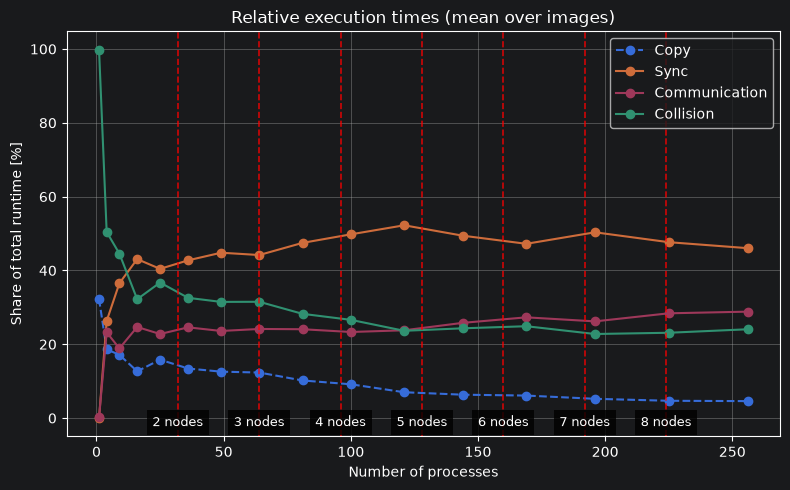

In [18]:
show_relative_plot(avg.copy(), "Relative execution times (mean over images)")
# show_absolute_times(avg.copy(), "Absolute execution times (mean over images)")

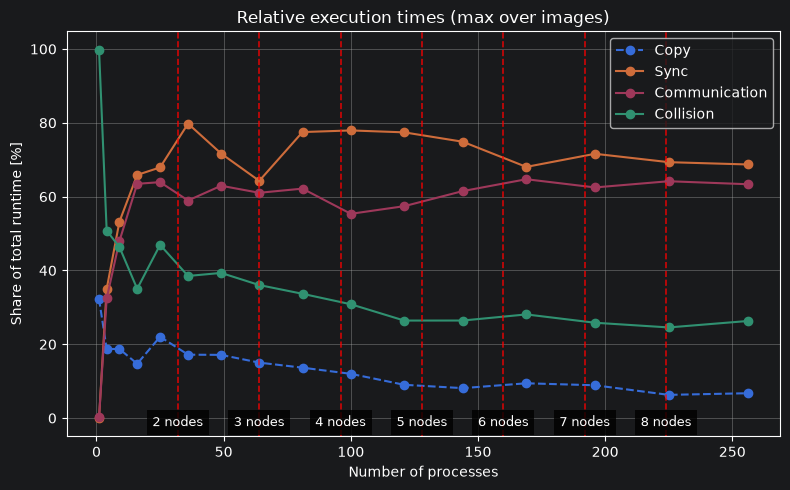

In [19]:
show_relative_plot(max_agg.copy(), "Relative execution times (max over images)")
# show_absolute_times(max_agg.copy(), "Absolute execution times (max over images)")

In [30]:
def heatmap_times(n, cmap, value, df = df, images_per_node = 64):

    subset = df[df["n"] == n].copy()

    if len(subset) != n:
        raise ValueError(f"Expected {n} rows for n={n}, got {len(subset)}.")

    side = int(np.sqrt(n))
    if side * side != n:
        raise ValueError("n must be a perfect square.")

    subset = subset.sort_values("i")
    comm = subset[value].to_numpy().reshape(side, side)
    fig, ax = plt.subplots(figsize=(6, 6))
    im = ax.imshow(
        comm,
        cmap=cmap,
        origin="upper",
        interpolation="nearest"
    )

    plt.colorbar(im, ax=ax, label=f"{value.capitalize()} time [s]")

    # numer obrazu w każdej komórce
    for row in range(side):
        for col in range(side):
            image_id = row * side + col + 1
            ax.text(
                col,
                row,
                str(image_id),
                ha="center",
                va="center",
                fontsize=8,
                color="black"
            )

    subset["node"] = ((subset["i"] - 1) // images_per_node) + 1
    node_grid = (
        ((subset["i"].to_numpy().reshape(side, side) - 1)
         // images_per_node) + 1
    )
    # granice pionowe
    for r in range(side):
        for c in range(side - 1):
            if node_grid[r, c] != node_grid[r, c + 1]:
                ax.plot(
                    [c + 0.5, c + 0.5],
                    [r - 0.5, r + 0.5],
                    '--',
                    color="black",
                    linewidth=1
                )

    # granice poziome
    for r in range(side - 1):
        for c in range(side):
            if node_grid[r, c] != node_grid[r + 1, c]:
                ax.plot(
                    [c - 0.5, c + 0.5],
                    [r + 0.5, r + 0.5],
                    '--',
                    color="black",
                    linewidth=1
                )

    ax.set_xticks(np.arange(side))
    ax.set_yticks(np.arange(side))

    ax.set_xlabel("Image column")
    ax.set_ylabel("Image row")
    ax.set_title(f"{value.capitalize()} time heatmap ({side}×{side} images)")

    plt.tight_layout()
    plt.show()

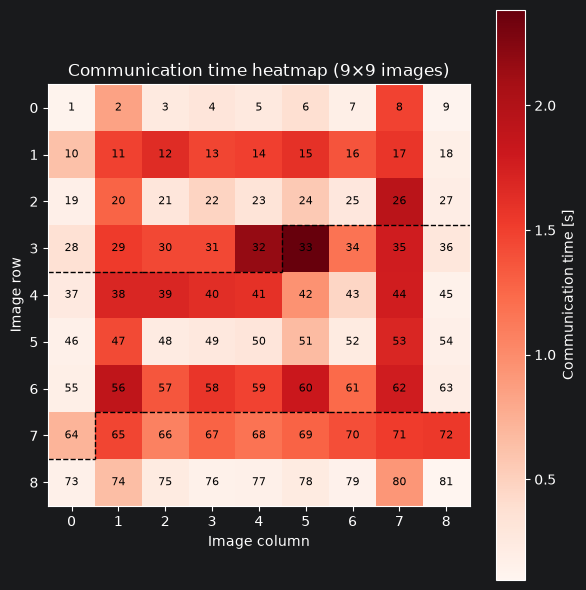

In [32]:
heatmap_times(81, "Reds", "communication", df = df, images_per_node = 32)

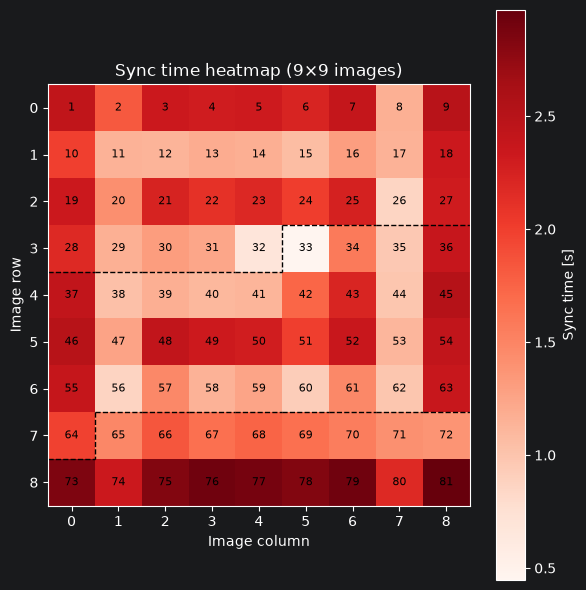

In [28]:
heatmap_times(81, "Reds", "sync", images_per_node = 32)

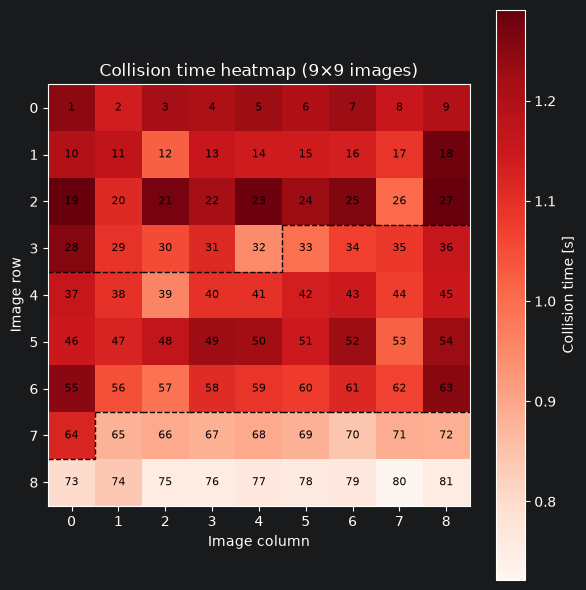

In [34]:
heatmap_times(81, "Reds", "collision", df = df, images_per_node = 32)

| Obrazy | Potrzebne nody | Dostępne sloty | Wykorzystanie ostatniego noda |
| -----: | -------------: | -------------: | ----------------------------: |
|      1 |              1 |             64 |                      **1.6%** |
|      4 |              1 |             64 |                      **6.2%** |
|      9 |              1 |             64 |                     **14.1%** |
|     16 |              1 |             64 |                     **25.0%** |
|     25 |              1 |             64 |                     **39.1%** |
|     36 |              1 |             64 |                     **56.2%** |
|     49 |              1 |             64 |                     **76.6%** |
|     64 |              1 |             64 |                    **100.0%** |
|     81 |              2 |            128 |                     **26.6%** |
|    100 |              2 |            128 |                     **56.2%** |
|    121 |              2 |            128 |                     **89.1%** |
|    144 |              3 |            192 |                     **25.0%** |
|    169 |              3 |            192 |                     **64.1%** |
|    196 |              4 |            256 |                      **6.2%** |
|    225 |              4 |            256 |                     **51.6%** |
|    256 |              4 |            256 |                    **100.0%** |


| Obrazy | Potrzebne nody | Dostępne sloty | Wykorzystanie ostatniego noda |
| -----: | -------------: | -------------: | ----------------------------: |
|      1 |              1 |             32 |                      **3.1%** |
|      4 |              1 |             32 |                     **12.5%** |
|      9 |              1 |             32 |                     **28.1%** |
|     16 |              1 |             32 |                     **50.0%** |
|     25 |              1 |             32 |                     **78.1%** |
|     36 |              2 |             64 |                     **12.5%** |
|     49 |              2 |             64 |                     **53.1%** |
|     64 |              2 |             64 |                    **100.0%** |
|     81 |              3 |             96 |                     **53.1%** |
|    100 |              4 |            128 |                     **12.5%** |
|    121 |              4 |            128 |                     **78.1%** |
|    144 |              5 |            160 |                     **50.0%** |
|    169 |              6 |            192 |                     **28.1%** |
|    196 |              7 |            224 |                     **12.5%** |
|    225 |              8 |            256 |                      **3.1%** |
|    256 |              8 |            256 |                    **100.0%** |


In [35]:
def node_stage_statistics(n, stage="collision", df=df, images_per_node=64):
    exp = df[df["n"] == n].copy().sort_values("i")
    exp["node"] = ((exp["i"] - 1) // images_per_node) + 1
    table = (
        exp
        .groupby("node")
        .agg(
            images=(stage, "size"),
            mean_time=(stage, "mean"),
            max_time=(stage, "max"),
            min_time=(stage, "min"),
            std_time=(stage, "std"),
        )
        .reset_index()
    )

    if len(table) > 1:
        last_mean = table.iloc[-1]["mean_time"]
        prev_mean = table.iloc[:-1]["mean_time"].mean()

        improvement = 100 * (prev_mean - last_mean) / prev_mean
    else:
        improvement = np.nan

    table["usage[%]"] = table["images"] / images_per_node * 100

    print(table)

    if not np.isnan(improvement):
        print(f"\nLast node speedup: {improvement:.1f}%")
    else:
        print("\nOnly one node.")

    # return table, improvement

In [44]:
node_stage_statistics(81, stage="collision", images_per_node=32)

   node  images  mean_time  max_time  min_time  std_time  usage[%]
0     1      32   1.173233  1.290630  0.947732  0.087963   100.000
1     2      32   1.119371  1.250952  0.958161  0.075283   100.000
2     3      17   0.821333  0.894085  0.721637  0.063084    53.125

Last node speedup: 28.3%


In [45]:
node_stage_statistics(81, stage="communication", images_per_node=32)

   node  images  mean_time  max_time  min_time  std_time  usage[%]
0     1      32   0.867804  2.165200  0.113827  0.654883   100.000
1     2      32   1.036811  2.382748  0.156490  0.704772   100.000
2     3      17   0.792945  1.547224  0.095802  0.579891    53.125

Last node speedup: 16.7%


In [46]:
def plot_last_node_improvement(
        df = df,
        stage="collision",
        images_per_node=64,
        connect=False,
        connect_by_node=False,
):
    data = []
    for n in sorted(df["n"].unique()):
        exp = df[df["n"] == n].copy()
        exp["node"] = ((exp["i"] - 1) // images_per_node) + 1
        stats = exp.groupby("node")[stage].mean().reset_index(name="mean_time")

        if len(stats) == 1:
            continue

        last_node = stats.iloc[-1]["mean_time"]
        other_nodes = stats.iloc[:-1]["mean_time"].mean()
        improvement = 100 * (other_nodes - last_node) / other_nodes
        last_usage = len(exp[exp["node"] == stats.iloc[-1]["node"]]) / images_per_node * 100

        data.append({
            "n": n,
            "nodes": int(np.ceil(float(n) / images_per_node)),
            "usage": last_usage,
            "improvement": improvement
        })

    result = pd.DataFrame(data).sort_values("usage")

    plt.figure(figsize=(7,5))
    plt.scatter(result["usage"], result["improvement"], s=70)

    if connect:
        plt.plot(result["usage"], result["improvement"], linewidth=1)
    if connect_by_node:
        for nodes_count, r in result.groupby("nodes"):
            plt.plot(r["usage"], r["improvement"], linewidth=1, label=f"{nodes_count} nodes")

    for _, row in result.iterrows():
        if connect_by_node:
            label_text = f"{str(int(row["n"]))} ({row['nodes']} nodes)"
        else:
            label_text = f"{str(int(row["n"]))}"
        plt.text(
            row["usage"] + 1,
            row["improvement"],
            label_text,
            fontsize=8
        )

    plt.xlabel("Last node usage [%]")
    plt.ylabel("Last node speedup [%]")
    plt.title(f"{stage.capitalize()} improvement on partially occupied last node")

    plt.grid(True)
    if connect_by_node:
        plt.legend()

    plt.tight_layout()
    plt.show()

    return result

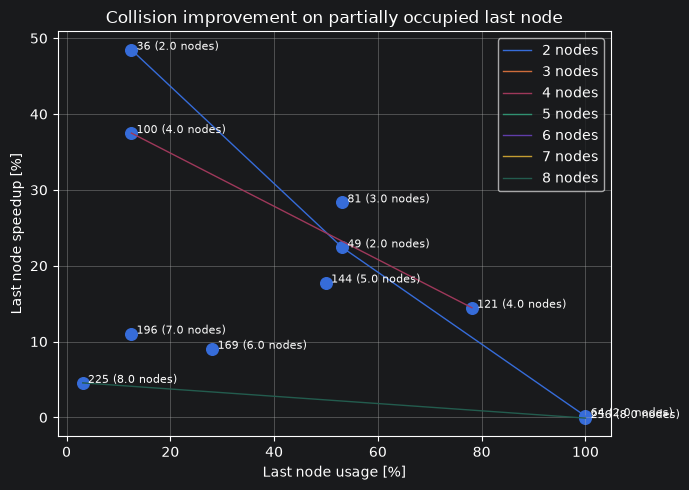

1536 x 1536 grid


In [48]:
plot_last_node_improvement(stage="collision", connect=False, connect_by_node=True, images_per_node=32)
print("1536 x 1536 grid")

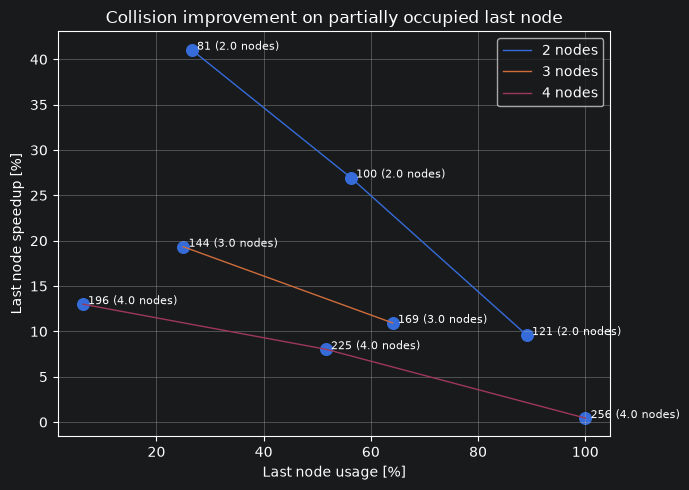

1536 x 1536 grid


In [49]:
plot_last_node_improvement(stage="collision", connect=False, connect_by_node=True, df=df_dense)
print("1536 x 1536 grid")